# Predicting Large Wildfires at Initial Attack
**Chelsea Veneziano | DSC 680 Applied Data Science | Bellevue University | November 2026**

**Goal:** Using only what is known when a fire is first reported, can a model flag the California wildfires most likely to escape initial attack?

**Targets**
- `ESCAPED`: the fire grew past 10 acres. This is CAL FIRE's goal for keeping fires small, so going past it means the first attack did not hold the fire.
- `LARGE`: the fire reached 100 acres or more (NWCG size class D and up).

**Hypotheses**
1. Weather and fuel conditions on the discovery day (dry fuels, low humidity, wind) raise the chance of escape.
2. Remote, undeveloped areas far from fire stations have more escapes.
3. The model catches escapes equally well in high and low social vulnerability communities.

**Data:** FPA FOD-Attributes (Pourmohamad et al., 2023, Zenodo, doi:10.5281/zenodo.8381129). It is the U.S. Forest Service national fire occurrence database (Short, 2022) with weather, terrain, vegetation, and social data added to each fire. All of the data is public.

**Notebook sections**
1. Setup and data download
2. Data preparation and cleaning
3. Exploratory analysis
4. Modeling
5. Evaluation and choosing a cutoff
6. What drives the predictions
7. Large-fire model
8. Fairness check
9. Summary of results

## 1. Setup and data download

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
print("pandas version:", pd.__version__)

pandas version: 2.1.4


Before downloading everything, I opened the 2020 file to check its size (308 columns) and confirm the key columns I need are there.

In [2]:
attr_2020 = pd.read_csv("data/2020_FPA_FOD_cons.csv", low_memory=False)
print(attr_2020.shape)

key_cols = ["FOD_ID", "STATE", "FIRE_SIZE", "DISCOVERY_DATE", "NWCG_GENERAL_CAUSE"]
print("Found:", [c for c in key_cols if c in attr_2020.columns])

(73221, 308)
Found: ['FOD_ID', 'STATE', 'FIRE_SIZE', 'DISCOVERY_DATE', 'NWCG_GENERAL_CAUSE']


The data comes as one CSV per year (1992–2020), about 5 GB total. This loop downloads each file from Zenodo. It skips files I already have and retries up to 3 times if the connection drops. If a download fails partway, it deletes the partial file so a broken file never gets used.

In [3]:
import os
import urllib.request

base_url = "https://zenodo.org/records/8381129/files/"

for year in range(1992, 2021):
    file_name = f"{year}_FPA_FOD_cons.csv"
    save_path = f"data/{file_name}"
    if os.path.exists(save_path):
        print(year, "already downloaded")
        continue
    for attempt in range(3):
        try:
            print("Downloading", year, "attempt", attempt + 1)
            urllib.request.urlretrieve(base_url + file_name + "?download=1", save_path)
            break
        except Exception as e:
            print("  Failed:", e)
            if os.path.exists(save_path):
                os.remove(save_path)

print("Done")


1992 already downloaded
1993 already downloaded
1994 already downloaded
1995 already downloaded
1996 already downloaded
1997 already downloaded
1998 already downloaded
1999 already downloaded
2000 already downloaded
2001 already downloaded
2002 already downloaded
2003 already downloaded
2004 already downloaded
2005 already downloaded
2006 already downloaded
2007 already downloaded
2008 already downloaded
2009 already downloaded
2010 already downloaded
2011 already downloaded
2012 already downloaded
2013 already downloaded
2014 already downloaded
2015 already downloaded
2016 already downloaded
2017 already downloaded
2018 already downloaded
2019 already downloaded
2020 already downloaded
Done


Each yearly file covers the whole U.S. I keep only California fires (`STATE == "CA"`) and stack the years into one DataFrame called `fires`.

In [4]:
frames = []

for year in range(1992, 2021):
    df = pd.read_csv(f"data/{year}_FPA_FOD_cons.csv", low_memory=False)
    ca = df[df["STATE"] == "CA"]
    frames.append(ca)
    print(year, len(ca))

fires = pd.concat(frames, ignore_index=True)
print("Total California fires:", fires.shape)


1992 10831
1993 8268
1994 8649
1995 7381
1996 9170
1997 7928
1998 6861
1999 8909
2000 6970
2001 8163
2002 7118
2003 7894
2004 7407
2005 10219
2006 12038
2007 13428
2008 10594
2009 9862
2010 8304
2011 8560
2012 7198
2013 8722
2014 6493
2015 7354
2016 7882
2017 9537
2018 9488
2019 6454
2020 10200
Total California fires: (251882, 308)


I save the California-only file so I don't have to reload all 29 national files again.

In [5]:
fires.to_csv("data/ca_fires_1992_2020.csv", index=False)
print("Saved California file")

Saved California file


A quick look at how rare the outcomes are. About 6% of California fires grew past 10 acres and about 2% reached 100+ acres. Because escapes are this rare, accuracy would be a misleading metric. A model that always says "contained" would be about 94% accurate and completely useless. That is why I focus on recall and PR-AUC later.

In [6]:
over_10 = (fires["FIRE_SIZE"] > 10).mean()
over_100 = (fires["FIRE_SIZE"] >= 100).mean()

print(f"Fires over 10 acres:  {over_10:.1%}")
print(f"Fires 100+ acres:     {over_100:.1%}")

Fires over 10 acres:  6.1%
Fires 100+ acres:     2.2%


## 2. Data preparation and cleaning

Reload the saved California file. It has 251,882 fires and 308 columns.

In [7]:
fires = pd.read_csv("data/ca_fires_1992_2020.csv", low_memory=False)
print(fires.shape)


(251882, 308)


List all 308 columns so I can decide which ones to keep.

In [8]:
print(", ".join(fires.columns))


FOD_ID, FPA_ID, SOURCE_SYSTEM_TYPE, SOURCE_SYSTEM, NWCG_REPORTING_AGENCY, NWCG_REPORTING_UNIT_ID, NWCG_REPORTING_UNIT_NAME, SOURCE_REPORTING_UNIT, SOURCE_REPORTING_UNIT_NAME, LOCAL_FIRE_REPORT_ID, LOCAL_INCIDENT_ID, FIRE_CODE, FIRE_NAME, ICS_209_PLUS_INCIDENT_JOIN_ID, ICS_209_PLUS_COMPLEX_JOIN_ID, MTBS_ID, MTBS_FIRE_NAME, COMPLEX_NAME, FIRE_YEAR, DISCOVERY_DATE, DISCOVERY_DOY, DISCOVERY_TIME, NWCG_CAUSE_CLASSIFICATION, NWCG_GENERAL_CAUSE, NWCG_CAUSE_AGE_CATEGORY, CONT_DATE, CONT_DOY, CONT_TIME, FIRE_SIZE, FIRE_SIZE_CLASS, LATITUDE, LONGITUDE, OWNER_DESCR, STATE, COUNTY, FIPS_CODE, FIPS_NAME, LatLong_State, LatLong_County, NPL, Mang_Type, Mang_Name, Des_Tp, GAP_Sts, GAP_Prity, EVH, EVT, EVH_1km, EVT_1km, EVC, EVC_1km, NAME, MOD_NDVI_12m, MOD_EVI_12m, Land_Cover, Land_Cover_1km, rpms, rpms_1km, Population, Popo_1km, GACCAbbrev, GACC_PL, GACC_New fire, GACC_New LF, GACC_Uncont LF, GACC_Type 1 IMTs, GACC_Type 2 IMTs, GACC_NIMO Teams, GACC_Area Command Teams, GACC_Fire Use Teams, GDP, pr_No

**Choosing columns and preventing data leakage**

I kept 37 columns. The main rule was: **only keep information that would be known when the fire is first reported.** Anything that describes what happened *after* the report would leak the answer into the model and make it look much better than it would be in real life. I removed:

- Containment date and time, and `FIRE_SIZE_CLASS` (these directly reveal how big the fire got)
- Fire names and incident report (ICS-209) and burn severity (MTBS) links, which mostly exist only for big fires
- 5-day weather averages, which are centered on the ignition date and include days after the fire started
- Counts of other fires burning in the region (GACC counts)

`FIRE_SIZE` is kept only to build the target. It is never used as a predictor. `RPL_THEMES` (CDC Social Vulnerability Index) is kept only for the fairness check, not as a predictor.

In [9]:
keep_cols = [
    # ID and target
    "FOD_ID", "FIRE_SIZE",
    # When
    "FIRE_YEAR", "DISCOVERY_DATE", "DISCOVERY_DOY", "DISCOVERY_TIME",
    # Cause and who responded
    "NWCG_CAUSE_CLASSIFICATION", "NWCG_GENERAL_CAUSE",
    "NWCG_REPORTING_AGENCY", "OWNER_DESCR",
    # Where
    "LATITUDE", "LONGITUDE", "FIPS_NAME", "GACCAbbrev",
    # Weather on the discovery day
    "tmmx", "rmin", "vs", "pr", "vpd", "fm100", "fm1000", "erc", "bi",
    # How unusual that weather was for the location
    "erc_Percentile", "vs_Percentile", "fm100_Percentile",
    # Terrain
    "Elevation", "Slope", "Aspect", "TRI",
    # Vegetation
    "Land_Cover", "NDVI-1day",
    # Human context
    "Population", "GHM", "No_FireStation_5.0km", "SDI",
    # Fairness check only, not a predictor
    "RPL_THEMES",
]

df = fires[keep_cols].copy()
print(df.shape)


(251882, 37)


Check what percent of each column is missing.

In [10]:
missing = df.isna().mean().sort_values(ascending=False) * 100
missing.round(1)


GACCAbbrev                   50.8
FIPS_NAME                    37.6
No_FireStation_5.0km         28.0
Population                   27.0
DISCOVERY_TIME               17.9
NDVI-1day                     3.6
vs_Percentile                 0.2
erc_Percentile                0.1
RPL_THEMES                    0.1
fm100_Percentile              0.0
bi                            0.0
Elevation                     0.0
Aspect                        0.0
Slope                         0.0
fm1000                        0.0
TRI                           0.0
Land_Cover                    0.0
GHM                           0.0
SDI                           0.0
erc                           0.0
FOD_ID                        0.0
fm100                         0.0
FIRE_SIZE                     0.0
pr                            0.0
vs                            0.0
rmin                          0.0
tmmx                          0.0
LONGITUDE                     0.0
LATITUDE                      0.0
OWNER_DESCR   

Several columns are missing a lot of values, so I checked whether the missing values are random or tied to certain years:
- **Population** is missing for every fire before 2000, and **discovery time** is missing for about 45–70% of fires before 2000. After 2000, both are almost complete.
- **GACCAbbrev** is missing for every fire before 2007.
- **Fire stations within 5 km** is missing for 16–40% of fires in every year. It has no zeros (the minimum is 1), so a missing value most likely means "no fire station within 5 km," not "unknown." 

In [11]:
print(df["No_FireStation_5.0km"].describe())

check_cols = ["GACCAbbrev", "Population", "No_FireStation_5.0km", "DISCOVERY_TIME"]
(df[check_cols].isna().groupby(df["FIRE_YEAR"]).mean() * 100).round(0)


count    181409.000000
mean          3.470743
std           3.139274
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max          42.000000
Name: No_FireStation_5.0km, dtype: float64


,GACCAbbrev,Population,No_FireStation_5.0km,DISCOVERY_TIME
FIRE_YEAR,,,,
1992,100.0,100.0,38.0,62.0
1993,100.0,100.0,31.0,70.0
1994,100.0,100.0,34.0,64.0
1995,100.0,100.0,28.0,68.0
1996,100.0,100.0,36.0,63.0
1997,100.0,100.0,33.0,65.0
1998,100.0,100.0,33.0,49.0
1999,100.0,100.0,36.0,44.0
2000,100.0,0.0,32.0,1.0


Based on the checks above:
- **Keep 2000–2020 only.** The earlier years have too much missing data, and recent years better reflect today's conditions.
- **Fill missing fire station counts with 0**, since missing means there was no station nearby.
- **Drop `FIPS_NAME`** (county name). It is missing 38% of the time, and latitude/longitude already cover location.

In [12]:
df = df[df["FIRE_YEAR"] >= 2000].copy()
df["No_FireStation_5.0km"] = df["No_FireStation_5.0km"].fillna(0)
df = df.drop(columns=["FIPS_NAME"])

print(df.shape)


(183885, 36)


My first idea for the 50% missing `GACCAbbrev` (Geographic Area Coordination Center) values was to fill them in from the nearest fires by location using KNN. The result showed regions that should not be in California (like SACC and AICC), so I checked the column more closely in the next cell.

In [13]:
from sklearn.neighbors import KNeighborsClassifier

has_gacc = df["GACCAbbrev"].notna()

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(df.loc[has_gacc, ["LATITUDE", "LONGITUDE"]], df.loc[has_gacc, "GACCAbbrev"])

df.loc[~has_gacc, "GACCAbbrev"] = knn.predict(df.loc[~has_gacc, ["LATITUDE", "LONGITUDE"]])

print(df["GACCAbbrev"].value_counts(dropna=False))


GACCAbbrev
OSCC    68054
ONCC    49044
SACC    37609
EACC     8666
SWCC     7047
RMCC     4751
GBCC     3627
NWCC     2954
NRCC     1412
AICC      721
Name: count, dtype: int64


This check showed that the GACC labels in this data span the whole state and are not reliable for California. It also showed that a few fires labeled CA are actually located in other states.

In [14]:
check = fires[fires["FIRE_YEAR"] >= 2007]
print(check["LatLong_State"].value_counts().head())

check.groupby("GACCAbbrev")[["LATITUDE", "LONGITUDE"]].agg(["min", "max"]).round(1)


LatLong_State
California    123953
Nevada            35
Arizona            8
Oregon             6
Name: count, dtype: int64


LATITUDE       LONGITUDE       
                min   max       min    max
GACCAbbrev                                
AICC           32.6  41.9    -124.3 -114.6
EACC           32.6  42.0    -124.4 -114.4
GBCC           32.6  42.0    -124.3 -114.5
NRCC           32.6  41.9    -124.2 -114.4
NWCC           32.6  42.0    -124.3 -114.6
ONCC           32.5  42.0    -124.4 -114.5
OSCC           32.5  42.0    -124.4 -114.5
RMCC           32.6  42.0    -124.3 -114.5
SACC           32.5  42.4    -124.4 -114.1
SWCC           32.6  42.0    -124.3 -114.2

So I:
- **Removed 190 fires** whose coordinates are outside California.
- **Dropped `GACCAbbrev`** and used **EPA Level III ecoregions** instead. Ecoregions are a better way to group locations because they are based on climate, terrain, and vegetation.

In [15]:
in_ca = fires.loc[df.index, "LatLong_State"] == "California"
print("Fires outside California removed:", (~in_ca).sum())
df = df[in_ca].copy()

df = df.drop(columns=["GACCAbbrev"])
df["ECO_L3"] = fires.loc[df.index, "Ecoregion_US_L3CODE"]

print(df.shape)
print(df["ECO_L3"].value_counts(dropna=False))


Fires outside California removed: 190
(183695, 36)
ECO_L3
6.0     45470
7.0     36840
85.0    28884
5.0     22021
78.0    13109
8.0      8350
14.0     6713
81.0     5655
1.0      5559
4.0      4633
9.0      4215
13.0     1831
80.0      342
NaN        73
Name: count, dtype: int64


Give the ecoregion codes readable names and drop the 73 fires with no ecoregion. This leaves **183,622 fires**.

In [16]:
eco_names = {
    1: "Coast Range",
    4: "Cascades",
    5: "Sierra Nevada",
    6: "Central CA Foothills & Coastal Mtns",
    7: "Central California Valley",
    8: "Southern California Mountains",
    9: "Eastern Cascades Slopes",
    13: "Central Basin and Range",
    14: "Mojave Basin and Range",
    78: "Klamath Mountains",
    80: "Northern Basin and Range",
    81: "Sonoran Basin and Range",
    85: "Southern CA Coast",
}

df = df[df["ECO_L3"].notna()].copy()
df["ECO_NAME"] = df["ECO_L3"].map(eco_names)

print(df.shape)
df["ECO_NAME"].value_counts()


(183622, 37)


ECO_NAME
Central CA Foothills & Coastal Mtns    45470
Central California Valley              36840
Southern CA Coast                      28884
Sierra Nevada                          22021
Klamath Mountains                      13109
Southern California Mountains           8350
Mojave Basin and Range                  6713
Sonoran Basin and Range                 5655
Coast Range                             5559
Cascades                                4633
Eastern Cascades Slopes                 4215
Central Basin and Range                 1831
Northern Basin and Range                 342
Name: count, dtype: int64

**Feature engineering and targets**
- `MONTH`: from the discovery date, to capture fire season.
- `DISCOVERY_HOUR`: hour of the day the fire was found (for example, 1430 becomes 14).
- `TIME_MISSING`: 1 if the discovery time is missing. I kept this as its own flag, since missing times may not be random.
- `ESCAPED`: 1 if the fire grew past 10 acres (5.6% of fires).
- `LARGE`: 1 if the fire reached 100 acres or more (2.0% of fires).

In [17]:
df["DISCOVERY_DATE"] = pd.to_datetime(df["DISCOVERY_DATE"], errors="coerce")
df["MONTH"] = df["DISCOVERY_DATE"].dt.month

df["TIME_MISSING"] = df["DISCOVERY_TIME"].isna().astype(int)
df["DISCOVERY_HOUR"] = df["DISCOVERY_TIME"] // 100

df["ESCAPED"] = (df["FIRE_SIZE"] > 10).astype(int)
df["LARGE"] = (df["FIRE_SIZE"] >= 100).astype(int)

print("Bad dates:", df["MONTH"].isna().sum())
print("Hour range:", df["DISCOVERY_HOUR"].min(), "to", df["DISCOVERY_HOUR"].max())
print(df[["ESCAPED", "LARGE"]].mean().round(3))


Bad dates: 0
Hour range: 0.0 to 23.0
ESCAPED    0.056
LARGE      0.020
dtype: float64


Save the cleaned dataset.

In [18]:
df.to_csv("data/ca_fires_clean.csv", index=False)
print("Saved cleaned file:", df.shape)


Saved cleaned file: (183622, 42)


## 3. Exploratory analysis

**Escape rate by month.** Summer is clearly the riskiest time. The escape rate goes from about 2% in January and February to about 7% in June.

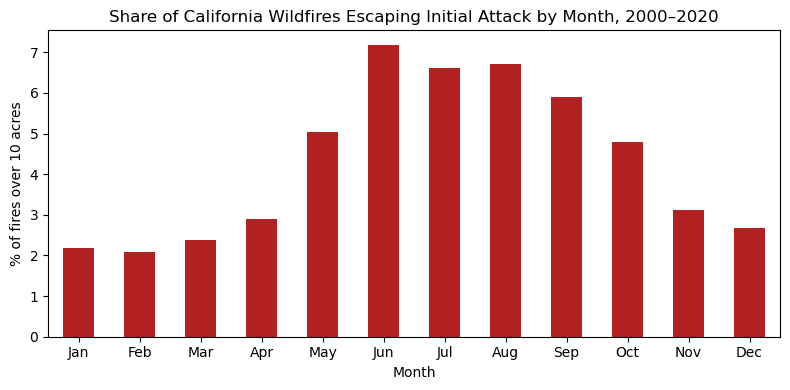

In [19]:
month_rate = df.groupby("MONTH")["ESCAPED"].mean() * 100

plt.figure(figsize=(8, 4))
month_rate.plot(kind="bar", color="firebrick")
plt.title("Share of California Wildfires Escaping Initial Attack by Month, 2000–2020")
plt.xlabel("Month")
plt.ylabel("% of fires over 10 acres")
plt.xticks(rotation=0)
plt.xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
plt.tight_layout()
plt.savefig("fig_escape_by_month.png", dpi=150)
plt.show()


**Escape rate by ecoregion.** The remote, dry regions on the east side of the state have the highest escape rates. The Northern Basin and Range is about 18% (based on only 342 fires), compared to about 2.5% in the Coast Range. This was my first sign that location and access would matter a lot. The `n=` labels show how many fires are in each region, so small regions can be read with caution.

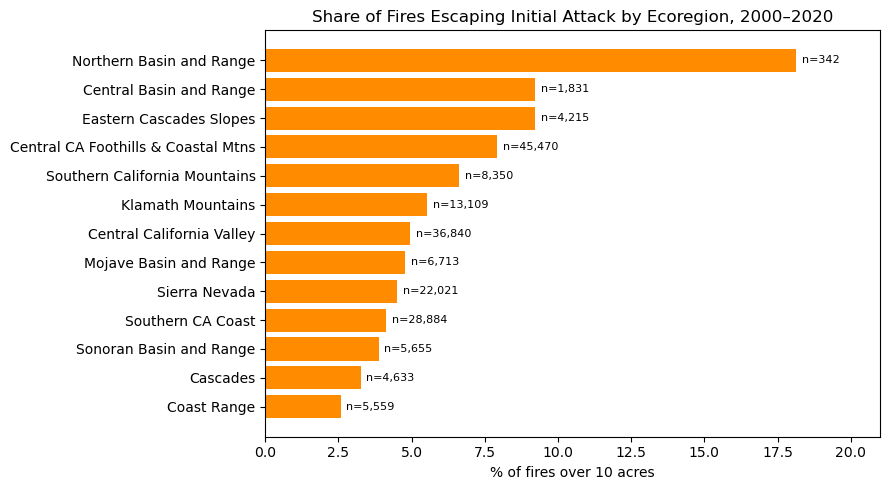

In [20]:
eco_stats = df.groupby("ECO_NAME")["ESCAPED"].agg(["mean", "count"]).sort_values("mean")
eco_stats["mean"] = eco_stats["mean"] * 100

plt.figure(figsize=(9, 5))
bars = plt.barh(eco_stats.index, eco_stats["mean"], color="darkorange")

for bar, n in zip(bars, eco_stats["count"]):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
             f"n={n:,}", va="center", fontsize=8)

plt.title("Share of Fires Escaping Initial Attack by Ecoregion, 2000–2020")
plt.xlabel("% of fires over 10 acres")
plt.xlim(0, 21)
plt.tight_layout()
plt.savefig("fig_escape_by_ecoregion.png", dpi=150)
plt.show()


**Escape rate by fuel dryness (ERC).** The percentile columns came in as text ranges (like "70-90%"), so I mapped them to numbers 1–6 in order. Surprisingly, the Energy Release Component shows almost no pattern with escape rate.

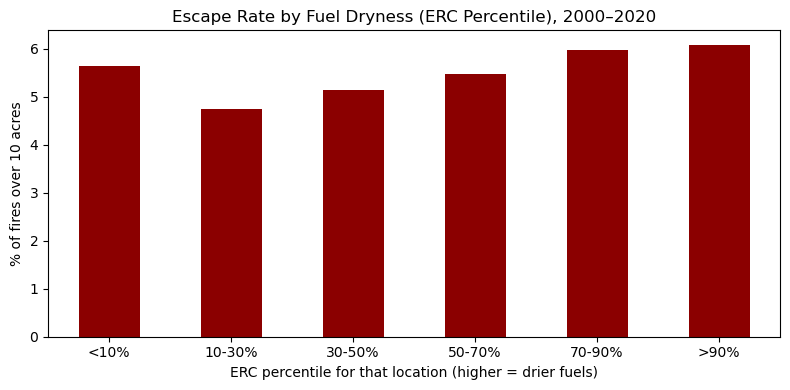

In [21]:
pct_order = {"<10%": 1, "10-30%": 2, "30-50%": 3, "50-70%": 4, "70-90%": 5, ">90%": 6}

for col in ["erc_Percentile", "vs_Percentile", "fm100_Percentile"]:
    if df[col].dtype == "object":
        df[col] = df[col].map(pct_order)

erc_rate = df.groupby("erc_Percentile")["ESCAPED"].mean() * 100
erc_rate.index = ["<10%", "10-30%", "30-50%", "50-70%", "70-90%", ">90%"]

plt.figure(figsize=(8, 4))
erc_rate.plot(kind="bar", color="darkred")
plt.title("Escape Rate by Fuel Dryness (ERC Percentile), 2000–2020")
plt.xlabel("ERC percentile for that location (higher = drier fuels)")
plt.ylabel("% of fires over 10 acres")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("fig_escape_by_erc.png", dpi=150)
plt.show()



Check that the percentile columns are now numbers and see which columns are still text (these will be one-hot encoded later).

In [22]:
print(df["erc_Percentile"].dtype)
print(df["erc_Percentile"].head(10).tolist())

df.dtypes[df.dtypes == "object"]


float64
[5.0, 5.0, 4.0, 5.0, 5.0, 6.0, 6.0, 5.0, 5.0, 6.0]


NWCG_CAUSE_CLASSIFICATION    object
NWCG_GENERAL_CAUSE           object
NWCG_REPORTING_AGENCY        object
OWNER_DESCR                  object
ECO_NAME                     object
dtype: object

Confirm the 1–6 values and how many are missing.

In [23]:
for col in ["erc_Percentile", "vs_Percentile", "fm100_Percentile"]:
    print(df[col].value_counts(dropna=False), "\n")


erc_Percentile
5.0    50710
6.0    43483
4.0    31169
3.0    27533
2.0    21508
1.0     9064
NaN      155
Name: count, dtype: int64 

vs_Percentile
2.0    37642
3.0    36091
5.0    35356
4.0    35010
1.0    20108
6.0    19050
NaN      365
Name: count, dtype: int64 

fm100_Percentile
2.0    47844
1.0    39807
3.0    35341
4.0    29120
5.0    23107
6.0     8359
NaN       44
Name: count, dtype: int64 



**Escape rate by weather percentile.** Dryer fuel moisture and higher wind both raise the escape rate. Fires in the driest fuel escaped about 6.8% of the time vs. 4.7% in the wettest, and the windiest 10% of days reached about 7.5%. Weather matters, but the differences are smaller than I expected.

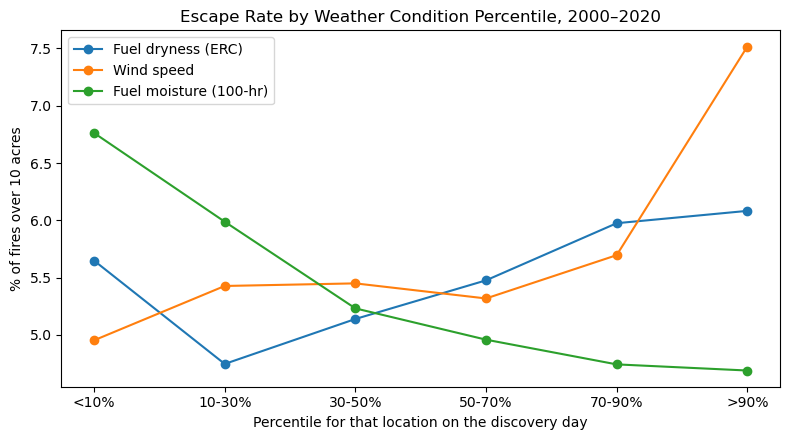

In [24]:
labels = ["<10%", "10-30%", "30-50%", "50-70%", "70-90%", ">90%"]
weather_vars = [
    ("erc_Percentile", "Fuel dryness (ERC)"),
    ("vs_Percentile", "Wind speed"),
    ("fm100_Percentile", "Fuel moisture (100-hr)"),
]

plt.figure(figsize=(8, 4.5))
for col, name in weather_vars:
    rate = df.groupby(col)["ESCAPED"].mean() * 100
    plt.plot(labels, rate.values, marker="o", label=name)

plt.title("Escape Rate by Weather Condition Percentile, 2000–2020")
plt.xlabel("Percentile for that location on the discovery day")
plt.ylabel("% of fires over 10 acres")
plt.legend()
plt.tight_layout()
plt.savefig("fig_escape_by_weather.png", dpi=150)
plt.show()


Save again now that the percentile columns are numeric.

In [25]:
df.to_csv("data/ca_fires_clean.csv", index=False)
print("Saved:", df.shape)


Saved: (183622, 42)


## 4. Modeling

**Features and a time-based split**

I use 26 numeric and 6 categorical features, all known at the time of the report.

Instead of a random split, I split by **time**: train on 2000–2016 and test on 2017–2020. This is how the model would really be used (trained on the past, used on future fires), and it is a stricter test, because recent fire seasons have been more extreme. The escape rate is similar in both sets (5.6% vs. 5.9%).

In [26]:
num_cols = ["MONTH", "DISCOVERY_HOUR", "TIME_MISSING", "LATITUDE", "LONGITUDE",
            "tmmx", "rmin", "vs", "pr", "vpd", "fm100", "fm1000", "erc", "bi",
            "erc_Percentile", "vs_Percentile", "fm100_Percentile",
            "Elevation", "Slope", "Aspect", "TRI", "NDVI-1day",
            "Population", "GHM", "No_FireStation_5.0km", "SDI"]

cat_cols = ["NWCG_CAUSE_CLASSIFICATION", "NWCG_GENERAL_CAUSE",
            "NWCG_REPORTING_AGENCY", "OWNER_DESCR", "ECO_NAME", "Land_Cover"]

df["Land_Cover"] = df["Land_Cover"].astype(str)

train = df[df["FIRE_YEAR"] <= 2016]
test = df[df["FIRE_YEAR"] >= 2017]

X_train = train[num_cols + cat_cols]
X_test = test[num_cols + cat_cols]
y_train = train["ESCAPED"]
y_test = test["ESCAPED"]

print("Train:", X_train.shape, "escape rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "escape rate:", round(y_test.mean(), 3))


Train: (147976, 32) escape rate: 0.056
Test:  (35646, 32) escape rate: 0.059


**Model 1: Logistic regression (baseline)**

A simple, easy-to-explain model to compare against. The preprocessing pipeline fills missing numbers with the median, scales numbers, and one-hot encodes categories. Putting it in a `Pipeline` means the medians and scaling are learned from the training data only, which avoids leakage from the test set.

`class_weight="balanced"` tells the model to pay more attention to the rare escapes. Otherwise it would learn to predict "contained" almost every time.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

log_model = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

log_model.fit(X_train, y_train)
print("Logistic regression trained")


Logistic regression trained


**Evaluation function**

I report several metrics because accuracy is misleading when only about 6% of fires escape:
- **ROC-AUC**: how well the model ranks risky fires above safe ones (0.5 = random guessing).
- **PR-AUC**: precision-recall area. This focuses on the rare class. Random guessing would score 0.059 here (the test escape rate).
- **Recall**: share of real escapes the model caught. This matters most, since missing an escape is the costly mistake.
- **Precision**: share of flagged fires that really escaped.

Logistic regression caught 62% of escapes, but only about 14% of its alerts were real.

In [28]:
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             recall_score, precision_score, f1_score,
                             confusion_matrix)

def evaluate(model, name, X, y):
    probs = model.predict_proba(X)[:, 1]
    preds = model.predict(X)
    print(name)
    print(confusion_matrix(y, preds))
    return {
        "Model": name,
        "ROC-AUC": roc_auc_score(y, probs),
        "PR-AUC": average_precision_score(y, probs),
        "Recall": recall_score(y, preds),
        "Precision": precision_score(y, preds),
        "F1": f1_score(y, preds),
    }

results = []
results.append(evaluate(log_model, "Logistic Regression", X_test, y_test))
pd.DataFrame(results).round(3)


Logistic Regression
[[25265  8292]
 [  785  1304]]


,Model,ROC-AUC,PR-AUC,Recall,Precision,F1
0,Logistic Regression,0.758,0.186,0.624,0.136,0.223


**Model 2: Random forest**

A random forest can pick up non-linear patterns and interactions (like wind mattering more in dry fuels). It ranks fires better than logistic regression (higher ROC-AUC and PR-AUC), but at the default cutoff it only catches 29% of escapes, which is too low for this use.

In [29]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("prep", clone(preprocess)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    )),
])

rf_model.fit(X_train, y_train)

results.append(evaluate(rf_model, "Random Forest", X_test, y_test))
pd.DataFrame(results).round(3)


Random Forest
[[31921  1636]
 [ 1487   602]]


,Model,ROC-AUC,PR-AUC,Recall,Precision,F1
0,Logistic Regression,0.758,0.186,0.624,0.136,0.223
1,Random Forest,0.778,0.214,0.288,0.269,0.278


**Model 3: Gradient boosting**

`HistGradientBoostingClassifier` builds trees one after another, each fixing the mistakes of the last. It handles missing values on its own, so I skip scaling here. It needs a dense (not sparse) one-hot matrix.

**Gradient boosting had the best ROC-AUC (0.793) and PR-AUC (0.230)**, about 4 times the random baseline, so I chose it as my final model.

In [30]:
from sklearn.ensemble import HistGradientBoostingClassifier

preprocess_dense = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

gb_model = Pipeline([
    ("prep", preprocess_dense),
    ("model", HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42,
    )),
])

gb_model.fit(X_train, y_train)

results.append(evaluate(gb_model, "Gradient Boosting", X_test, y_test))
pd.DataFrame(results).round(3)


Gradient Boosting
[[27751  5806]
 [  851  1238]]


,Model,ROC-AUC,PR-AUC,Recall,Precision,F1
0,Logistic Regression,0.758,0.186,0.624,0.136,0.223
1,Random Forest,0.778,0.214,0.288,0.269,0.278
2,Gradient Boosting,0.793,0.230,0.593,0.176,0.271


## 5. Evaluation and choosing a cutoff

**Cross-validation and picking a cutoff**

5-fold cross-validation on the training years gives a ROC-AUC of 0.805, close to the test score, so the model is not badly overfit.

A model outputs a probability, and the cutoff decides when a fire gets flagged. I looked for the highest cutoff that still catches at least 70% of escapes. Using shuffled folds gave 0.51.

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(gb_model, X_train, y_train, cv=cv,
                              method="predict_proba")[:, 1]

print("5-fold CV ROC-AUC (training years):", round(roc_auc_score(y_train, oof_probs), 3))

thresholds = np.linspace(0.05, 0.95, 91)
recalls = [recall_score(y_train, oof_probs >= t) for t in thresholds]
best_t = max(t for t, r in zip(thresholds, recalls) if r >= 0.70)

print("Chosen cutoff:", round(best_t, 2))


5-fold CV ROC-AUC (training years): 0.805
Chosen cutoff: 0.51


Shuffled folds mix years together, which is not how the model would be used. So I also picked the cutoff in a **time-based** way: train on 2000–2012, check on 2013–2016, and choose the highest cutoff with recall of 70% or more. That gave **0.49**, which I use as my final cutoff.

On the 2017–2020 test years, the 0.49 cutoff caught about 60% of escapes, not the 70% it reached on 2013–2016. This drop suggests recent fire seasons behave differently, which is why the model would need to be retrained regularly.

In [32]:
early = train[train["FIRE_YEAR"] <= 2012]
late = train[train["FIRE_YEAR"] >= 2013]

gb_check = clone(gb_model)
gb_check.fit(early[num_cols + cat_cols], early["ESCAPED"])
late_probs = gb_check.predict_proba(late[num_cols + cat_cols])[:, 1]

recalls = [recall_score(late["ESCAPED"], late_probs >= t) for t in thresholds]
time_t = max(t for t, r in zip(thresholds, recalls) if r >= 0.70)
print("Time-based cutoff:", round(time_t, 2))

test_probs = gb_model.predict_proba(X_test)[:, 1]
for name, t in [("Default", 0.50), ("Shuffled CV", best_t), ("Time-based", time_t)]:
    preds = test_probs >= t
    print(f"{name} ({t:.2f}): recall {recall_score(y_test, preds):.3f}, "
          f"precision {precision_score(y_test, preds):.3f}, flagged {preds.sum():,}")


Time-based cutoff: 0.49
Default (0.50): recall 0.593, precision 0.176, flagged 7,044
Shuffled CV (0.51): recall 0.579, precision 0.178, flagged 6,782
Time-based (0.49): recall 0.603, precision 0.172, flagged 7,324


**Final confusion matrix (gradient boosting, cutoff 0.49, test years 2017–2020)**

- Caught **1,259 of 2,089** escapes (60%) and missed 830.
- Flagged 7,324 fires, about **1 in 5** new fires.
- 6,065 false alarms, about 30% fewer than logistic regression for a similar recall. Roughly 5 out of 6 alerts are false alarms, so the model works as a "take a closer look" tool, not a final answer.

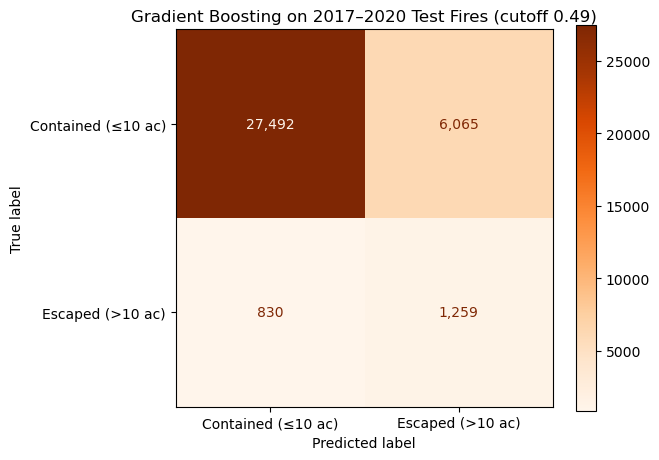

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay

final_preds = (test_probs >= time_t).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test, final_preds,
    display_labels=["Contained (≤10 ac)", "Escaped (>10 ac)"],
    cmap="Oranges",
    values_format=",",
)
plt.title("Gradient Boosting on 2017–2020 Test Fires (cutoff 0.49)")
plt.tight_layout()
plt.savefig("fig_confusion_matrix.png", dpi=150)
plt.show()


## 6. What drives the predictions

**Permutation importance (individual features).** I shuffled each feature and measured how much the test ROC-AUC dropped. The top features are discovery hour, human modification of the land (GHM), population, and the number of nearby fire stations.

One caveat: many weather features are strongly correlated with each other. When one is shuffled, the model can lean on the others, which makes each one look less important than the group really is. So I also measured importance by group in the next cell.

In [34]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(gb_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=42, n_jobs=-1)

imp = pd.Series(perm.importances_mean, index=X_test.columns)
imp.sort_values(ascending=False).round(4)


DISCOVERY_HOUR               0.0320
GHM                          0.0319
Population                   0.0241
No_FireStation_5.0km         0.0128
NWCG_GENERAL_CAUSE           0.0083
NDVI-1day                    0.0082
Elevation                    0.0057
SDI                          0.0052
vpd                          0.0050
tmmx                         0.0050
ECO_NAME                     0.0048
LONGITUDE                    0.0038
Land_Cover                   0.0033
TRI                          0.0033
OWNER_DESCR                  0.0025
LATITUDE                     0.0023
bi                           0.0021
vs_Percentile                0.0017
fm1000                       0.0016
vs                           0.0016
MONTH                        0.0014
Aspect                       0.0014
rmin                         0.0011
NWCG_REPORTING_AGENCY        0.0010
Slope                        0.0009
NWCG_CAUSE_CLASSIFICATION    0.0006
erc                          0.0001
fm100                       

**Grouped permutation importance.** This shuffles a whole group of related features at once.

**Human access and development (population, land development, nearby fire stations) was the most important group, with an AUC drop of 0.136, about 3 times more than weather (0.046).** My interpretation is that remote fires tend to be found later and take longer to reach, so they have more time to grow. **This supports Hypothesis 2. Hypothesis 1 is also supported**, since weather is the second most important group, though weaker than I expected.

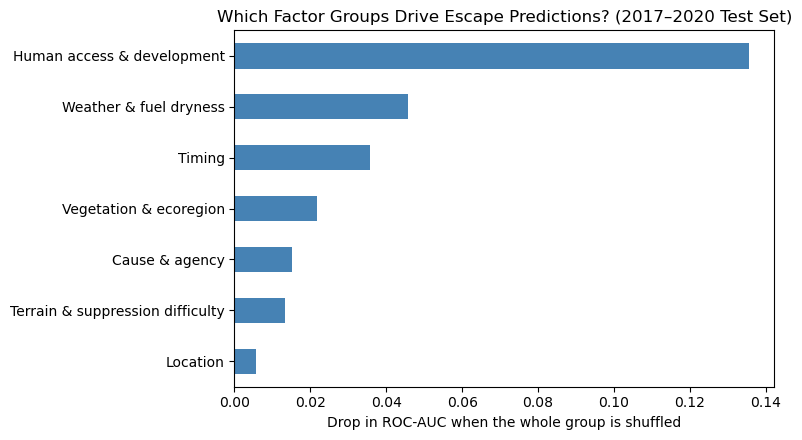

Human access & development          0.1355
Weather & fuel dryness              0.0458
Timing                              0.0358
Vegetation & ecoregion              0.0217
Cause & agency                      0.0151
Terrain & suppression difficulty    0.0133
Location                            0.0057
dtype: float64

In [35]:
groups = {
    "Weather & fuel dryness": ["tmmx", "rmin", "vs", "pr", "vpd", "fm100", "fm1000",
                               "erc", "bi", "erc_Percentile", "vs_Percentile",
                               "fm100_Percentile"],
    "Human access & development": ["Population", "GHM", "No_FireStation_5.0km"],
    "Timing": ["MONTH", "DISCOVERY_HOUR", "TIME_MISSING"],
    "Terrain & suppression difficulty": ["Elevation", "Slope", "Aspect", "TRI", "SDI"],
    "Vegetation & ecoregion": ["NDVI-1day", "Land_Cover", "ECO_NAME"],
    "Cause & agency": ["NWCG_CAUSE_CLASSIFICATION", "NWCG_GENERAL_CAUSE",
                       "NWCG_REPORTING_AGENCY", "OWNER_DESCR"],
    "Location": ["LATITUDE", "LONGITUDE"],
}

base_auc = roc_auc_score(y_test, gb_model.predict_proba(X_test)[:, 1])
rng = np.random.default_rng(42)
group_imp = {}

for name, cols in groups.items():
    drops = []
    for _ in range(5):
        order = rng.permutation(len(X_test))
        shuffled_part = X_test[cols].iloc[order]
        shuffled_part.index = X_test.index
        X_shuffled = X_test.copy()
        X_shuffled[cols] = shuffled_part
        auc = roc_auc_score(y_test, gb_model.predict_proba(X_shuffled)[:, 1])
        drops.append(base_auc - auc)
    group_imp[name] = np.mean(drops)

group_imp = pd.Series(group_imp).sort_values()

plt.figure(figsize=(8, 4.5))
group_imp.plot(kind="barh", color="steelblue")
plt.title("Which Factor Groups Drive Escape Predictions? (2017–2020 Test Set)")
plt.xlabel("Drop in ROC-AUC when the whole group is shuffled")
plt.tight_layout()
plt.savefig("fig_group_importance.png", dpi=150)
plt.show()

group_imp.sort_values(ascending=False).round(4)


## 7. Large-fire model (100+ acres)

The same gradient boosting setup, trained to predict fires that reach 100+ acres. Only 2.2% of test fires got that big. The model reached a **ROC-AUC of 0.821** and PR-AUC of 0.143 (random baseline 0.022), catching 467 of 782 large fires. Precision is low (about 9%), as expected for such a rare event.

In [36]:
y_train_large = train["LARGE"]
y_test_large = test["LARGE"]

gb_large = clone(gb_model)
gb_large.fit(X_train, y_train_large)

large_results = evaluate(gb_large, "Gradient Boosting (100+ acres)", X_test, y_test_large)
print("Test large-fire rate:", round(y_test_large.mean(), 3))

pd.DataFrame([results[2], large_results]).round(3)


Gradient Boosting (100+ acres)
[[30197  4667]
 [  315   467]]
Test large-fire rate: 0.022


,Model,ROC-AUC,PR-AUC,Recall,Precision,F1
0,Gradient Boosting,0.793,0.230,0.593,0.176,0.271
1,Gradient Boosting (100+ acres),0.821,0.143,0.597,0.091,0.158


## 8. Fairness check

I checked whether the model works equally well across communities, using the CDC Social Vulnerability Index (`RPL_THEMES`). Values of -999 mean "no data," so I set them to missing. Then I split fires into four equal groups and measured recall in each group.

**Result:** The model caught about 62–64% of escapes in the three less vulnerable groups, but only **48% in the most vulnerable group**. It also flagged fewer fires there (11% vs. about 24%). Recall also varied a lot by ecoregion, from 28% in the Coast Range to 86% in the Northern Basin. **Hypothesis 3 is not supported.**

In [37]:
fair = test[["ECO_NAME", "RPL_THEMES"]].copy()
fair["actual"] = y_test.values
fair["pred"] = final_preds
fair.loc[fair["RPL_THEMES"] < 0, "RPL_THEMES"] = np.nan
fair["SVI_GROUP"] = pd.qcut(fair["RPL_THEMES"], 4,
                            labels=["Low", "Med-Low", "Med-High", "High"])

def group_recall(g):
    escaped = g[g["actual"] == 1]
    return pd.Series({
        "Fires": len(g),
        "Escapes": len(escaped),
        "Recall": escaped["pred"].mean(),
        "Flag rate": g["pred"].mean(),
    })

print(fair.groupby("SVI_GROUP", observed=True).apply(group_recall).round(3))
print()
print(fair.groupby("ECO_NAME").apply(group_recall).sort_values("Recall").round(3))



            Fires  Escapes  Recall  Flag rate
SVI_GROUP                                    
Low        8902.0    541.0   0.619      0.228
Med-Low    8902.0    601.0   0.637      0.249
Med-High   8912.0    598.0   0.620      0.235
High       8890.0    345.0   0.484      0.110

                                      Fires  Escapes  Recall  Flag rate
ECO_NAME                                                               
Coast Range                           827.0     18.0   0.278      0.050
Sonoran Basin and Range              1232.0     51.0   0.392      0.127
Cascades                              727.0     30.0   0.467      0.139
Sierra Nevada                        3490.0    197.0   0.477      0.174
Southern CA Coast                    6594.0    269.0   0.528      0.117
Central California Valley            8358.0    327.0   0.544      0.144
Eastern Cascades Slopes               811.0    116.0   0.578      0.307
Klamath Mountains                    1789.0    133.0   0.579      0.263
Cen

**Does removing the human features fix it?** One common idea is "fairness through unawareness": remove the features linked to the group and retrain. I removed population, land development, and fire stations.

AUC dropped only slightly (0.793 to 0.782), but recall in the most vulnerable group got **worse** (46%), not better. Removing features did not fix the gap. A real fix would need something like a separate cutoff per group or more data from those areas, which I discuss in the white paper.

In [38]:
human_cols = ["Population", "GHM", "No_FireStation_5.0km"]
num_no_human = [c for c in num_cols if c not in human_cols]

prep_nh = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_no_human),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
gb_nh = Pipeline([("prep", prep_nh), ("model", clone(gb_model.named_steps["model"]))])
gb_nh.fit(X_train, y_train)

nh_probs = gb_nh.predict_proba(X_test)[:, 1]
fair["pred_nh"] = (nh_probs >= time_t).astype(int)

print("ROC-AUC with human features:   ", round(roc_auc_score(y_test, test_probs), 3))
print("ROC-AUC without human features:", round(roc_auc_score(y_test, nh_probs), 3))
print("Overall recall without:        ", round(recall_score(y_test, fair["pred_nh"]), 3))

pd.DataFrame({
    "Recall with": fair.groupby("SVI_GROUP", observed=True).apply(
        lambda g: g.loc[g["actual"] == 1, "pred"].mean()),
    "Recall without": fair.groupby("SVI_GROUP", observed=True).apply(
        lambda g: g.loc[g["actual"] == 1, "pred_nh"].mean()),
}).round(3)


ROC-AUC with human features:    0.793
ROC-AUC without human features: 0.782
Overall recall without:         0.589


,Recall with,Recall without
SVI_GROUP,,
Low,0.619,0.628
Med-Low,0.637,0.631
Med-High,0.620,0.584
High,0.484,0.464


## 9. Summary of results

| Model (test years 2017–2020) | ROC-AUC | PR-AUC | Recall |
|---|---|---|---|
| Logistic regression | 0.758 | 0.186 | 0.62 |
| Random forest | 0.778 | 0.214 | 0.29 |
| **Gradient boosting** | **0.793** | **0.230** | **0.59** |

- **Final model:** gradient boosting at a 0.49 cutoff flagged about 1 in 5 new fires and caught 60% of the fires that escaped.
- **Large fires (100+ acres):** ROC-AUC 0.821.
- **H1 (weather and fuel): supported.** Dry fuels and wind raise escape rates, but less than expected.
- **H2 (location and access): supported.** Human access and development was the strongest group, about 3 times more important than weather.
- **H3 (fairness): not supported.** Recall was 48% in the most vulnerable communities vs. about 62% elsewhere.

**Limitations:** about 5 of 6 alerts are false alarms; recall dropped on the most recent years; the public data does not include what resources were sent or how fast they arrived; weather is daily, not hourly.

**Reproducibility:** all models use `random_state=42`. Run the notebook from top to bottom with a `data/` folder next to it, and it will download the data and recreate every result and chart.